> Historical v1 notebook. Its saved outputs and service API describe commit f2dd580. For the current Colhound service use service_v2.ipynb and docs/service_v2_results.md. Do not use v1 timings or effects as v2 measurements.

# RWB «Отгрузки без простоев» — сервис прогноза и вызова машин

Задача кейса — не только угадать `target_1h`, а **решить, когда вызывать машину на склад**, чтобы меньше машин простаивало и меньше груза ждало транспорта. Поэтому финальное решение — сервис из трёх частей:

1. **Прогноз** отгрузок каждого маршрута на 4 часа вперёд, с диапазоном «с вероятностью 80/90% не больше X».
2. **План вызова машин**: по грузу у ворот, прогнозу и времени подачи — во сколько вызывать следующую машину.
3. **Контроль качества**: ежедневные метрики, тревоги по перекосу суммы и запасной прогноз при пропусках данных.

| | Итог |
|---|---|
| Модель | одна LightGBM (Huber) с профилями маршрутов, 8 моделей по шагам, только CPU |
| Точность (14 дней, прогноз из 10:30) | 0.3271 без подбора множителя; ансамбль v3 — 0.3249, бейзлайн организаторов — 0.367 |
| Обучение / прогноз 1000 маршрутов | ≈4 мин на CPU / 2 с |
| Диапазоны на отложенной неделе | в 80%-диапазон попало 79.9% фактов, в 90% — 91.1% |
| Вызов машин (подача 1 ч) | 20 мин потерь на машину против 60 при вызове «по факту» и 23–28 у простых правил |
| Недогруженных машин | 6 в день против 31–62 у простых правил |

Пульт диспетчера — `outputs/dispatch_board.html` (создаёт `python scripts/pipeline.py report`), открывается в браузере без интернета.

Ноутбук «тонкий»: код в `src/rwb/` и `scripts/`. Он читает сохранённые прогнозы из `models/rolling/` и результаты из `reports/service/`; `RETRAIN = True` пересчитывает всё (≈15 минут на CPU).

In [1]:
import sys, json, subprocess, logging
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent  # запуск из notebooks/
sys.path.insert(0, str(ROOT / "src"))

from rwb.data import HORIZON, load_panel
from rwb.features import DAY, cumsums
from rwb.backtest import score_origins
from rwb.service import Service

RETRAIN = False
PY = sys.executable
if RETRAIN:
    for cmd in (["scripts/rolling.py", "--folds", "2", "--final"], ["scripts/service_backtest.py"],
                ["scripts/pipeline.py", "train"], ["scripts/pipeline.py", "report"]):
        subprocess.run([PY, *cmd], cwd=ROOT, check=True)

panel = load_panel()
cums = cumsums(panel)
BT = json.loads((ROOT / "reports/service/lean.json").read_text(encoding="utf-8"))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25})
print("данные:", panel.times[0], "—", panel.times[-1], "| маршрутов:", panel.n_routes)

данные: 2025-07-28 00:00:00 — 2025-11-01 10:30:00 | маршрутов: 1000


## 1. Почему одна лёгкая модель, а не ансамбль

На лидерборде ансамбль v3 получил **0.339**, а v2 — **0.323**, хотя на валидации v3 был лучше (0.3249 против 0.3268). Разбор показал: по точкам они почти одинаковы, но сумма прогноза v3 на 1.6% ниже, а метрика добавляет **|сумма прогноза / сумма факта − 1|**. Каждый 1% промаха по сумме дня стоит 0.01 балла — больше, чем все улучшения моделей вместе. Большая часть разницы пришла из подобранного на валидации множителя (1.0075 у v3 против ≈1.02 у v2).

Отсюда требования к рабочей модели:
- **без подбираемого множителя**: у LightGBM с функцией потерь Huber оптимальный множитель на трёх неделях проверки 1.00, она сама не занижает сумму;
- **уровень суммы контролируется отдельно** (раздел 5);
- **простота**: ансамбль v3 выигрывает 0.002 — меньше дневного шума метрики, но требует 40 моделей, двух библиотек и видеокарты.

| | Валидация (14 дней) | Лидерборд | Моделей | Железо | Обучение |
|---|---|---|---|---|---|
| Ансамбль v2 | 0.3268 | 0.323 | 64 | GPU + CPU | ≈2.5 ч |
| Ансамбль v3 | 0.3249 | 0.339 | 40 | GPU + CPU | ≈1.5 ч |
| **LightGBM Huber + профили** | 0.3271 (3 недели: 0.3284) | — | 8 | CPU | ≈4 мин |

Насколько вообще можно верить публичному баллу? Симуляция на 14 днях валидации: строки дня случайно делятся пополам на «публичную» и «приватную» части.

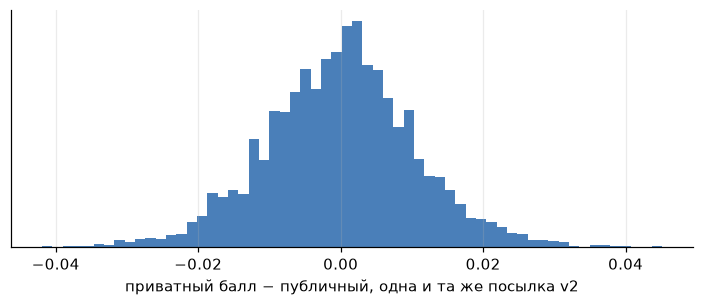

разброс приватный−публичный: ±0.021 (95%)
разброс разницы двух моделей между половинами: σ = 0.0053; наш разрыв v3−v2 на публичной части 0.016 ≈ 3σ


In [2]:
def blend(sub):
    cfg = json.loads((ROOT / f"submissions/{sub}.json").read_text(encoding="utf-8"))
    return np.concatenate([sum(w * np.load(ROOT / f"models/oof/{n}.npz")[f"pred_{f}"] for n, w in zip(cfg["models"], cfg["weights"]))
                           for f in ("fold1", "fold0")])

Y = np.nan_to_num(np.concatenate([np.load(ROOT / "models/oof/xgb_lr_bag3.npz")[f"truth_{f}"] for f in ("fold1", "fold0")]))
V2, V3 = blend("ensemble_v2"), blend("ensemble_v3")
sc = lambda p, y: np.abs(p - y).sum() / y.sum() + abs(p.sum() / y.sum() - 1)
rng = np.random.default_rng(0)
gap, flip = [], []
for i in range(len(Y)):
    for _ in range(200):
        m = rng.random(Y.shape[1:]) < 0.5
        gap.append(sc(V2[i][~m], Y[i][~m]) - sc(V2[i][m], Y[i][m]))
        flip.append((sc(V3[i][~m], Y[i][~m]) - sc(V2[i][~m], Y[i][~m])) - (sc(V3[i][m], Y[i][m]) - sc(V2[i][m], Y[i][m])))
gap, flip = np.array(gap), np.array(flip)
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.hist(gap, bins=60, color="#1d5fa8", alpha=0.8)
ax.set_xlabel("приватный балл − публичный, одна и та же посылка v2"); ax.set_yticks([])
plt.show()
print(f"разброс приватный−публичный: ±{np.quantile(np.abs(gap), 0.95):.3f} (95%)")
print(f"разброс разницы двух моделей между половинами: σ = {flip.std():.4f}; наш разрыв v3−v2 на публичной части 0.016 ≈ {0.016 / flip.std():.0f}σ")

Вывод: приватный балл одной и той же посылки может отличаться от публичного на ±0.02 — у всех команд. Но **порядок моделей устойчив**: разрыв 0.016 между v3 и v2 — это около 3σ, так что v2 почти наверняка лучше и на приватной части. Финальная посылка соревнования — **v2** (`submissions/ensemble_v2.csv`).

## 2. Модель

Прогноз каждого шага = **сезонная база + поправка модели**. База — половина среднего за последние сутки и половина сглаженного профиля дня маршрута за 28 дней (профили 1000 маршрутов сжаты SVD до 12 типовых форм, это убирает шум мелких маршрутов). Модель LightGBM с потерей Huber учит поправку в долях обычного уровня маршрута по ≈170 признакам: последние часы, то же время вчера и неделю назад, статусы заказов в работе на этом и предыдущем складе, время суток.

Для сервиса модель проверена «как в жизни»: обучена один раз в начале недели и давала прогноз **из каждого получаса** следующей недели (336 моментов × 1000 маршрутов), не переобучаясь.

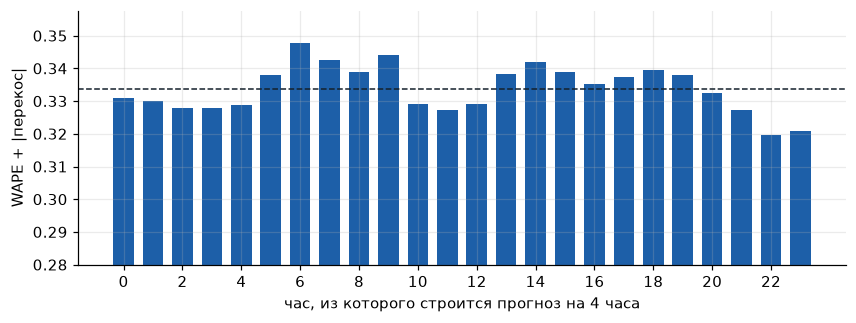

среднее по всем получасам недели 0.3337, из 10:30 (как в тесте) 0.3279


In [3]:
by_hour = pd.Series({int(k): v for k, v in BT["point"]["by_hour"].items()}).sort_index()
fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(by_hour.index, by_hour.values, color="#1d5fa8", width=0.7)
ax.axhline(BT["point"]["all_origins"], color="#15212c", lw=1, ls="--")
ax.set_ylim(0.28, by_hour.max() + 0.01); ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("час, из которого строится прогноз на 4 часа"); ax.set_ylabel("WAPE + |перекос|")
plt.show()
print(f"среднее по всем получасам недели {BT['point']['all_origins']:.4f}, из 10:30 (как в тесте) {BT['point']['at_10_30']:.4f}")

Качество ровное в течение суток (0.32–0.35): модель годится не только для теста в 10:30, а для работы каждые полчаса.

Стабильность по неделям (прогноз из 10:30, модель обучена до начала недели):

In [4]:
res = {}
for line in open(ROOT / "models/results.jsonl", encoding="utf-8"):
    d = json.loads(line)
    if d["name"] in ("lgbm_huber_blr3", "xgb_blr3"):
        res[d["name"]] = d["summary"]
weeks = {"fold0": "25–31 окт", "fold1": "18–24 окт", "fold2": "11–17 окт"}
pd.DataFrame({n: {weeks[k]: round(v, 4) for k, v in s.items() if k in weeks} for n, s in res.items()}).rename(
    columns={"lgbm_huber_blr3": "LightGBM Huber (сервис)", "xgb_blr3": "XGBoost (основа v3)"})

,XGBoost (основа v3),LightGBM Huber (сервис)
25–31 окт,0.3312,0.3279
18–24 окт,0.3299,0.3264
11–17 окт,0.3351,0.3308


Без всякого множителя LightGBM Huber даёт в среднем за три недели 0.3284, и лучший множитель для неё ровно 1.00. XGBoost из v3 без множителя хуже (0.3321) и догоняет (0.3279) только с подобранным множителем 1.01 — той самой деталью, что подвела на лидерборде. Для сервиса это решающий аргумент: меньше чисел, подогнанных под валидацию.

## 3. Диапазоны прогноза

Для решения о машине мало одной цифры: нужно понимать, сколько может прийти в плохом сценарии. Диапазоны строятся **конформным методом**: на неделе калибровки собираются относительные ошибки прогноза по шагу и размеру маршрута (мелкие маршруты шумнее), на новой неделе их квантили превращают прогноз в диапазон. Модель для этого не переобучается.

Проверка на следующей неделе — какая доля фактов попала в диапазон:

,должно,попало (все получасы),попало (из 10:30),ширина / прогноз
80%,80%,79.9%,81.4%,1.06
90%,90%,91.1%,92.0%,1.39
50%,50%,50.0%,51.2%,0.55


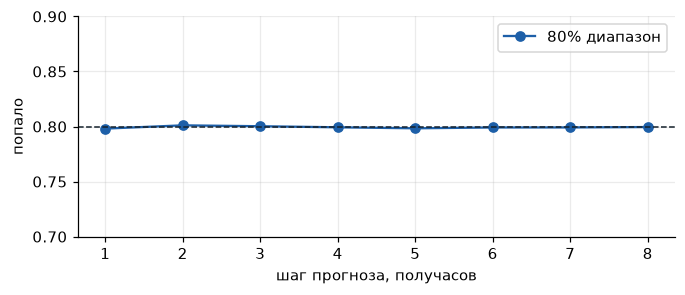

In [5]:
iv = BT["intervals"]
tab = pd.DataFrame({k: {"должно": k, "попало (все получасы)": f"{v['coverage']:.1%}", "попало (из 10:30)": f"{v['coverage_10_30']:.1%}",
                        "ширина / прогноз": f"{v['rel_width']:.2f}"} for k, v in iv.items() if isinstance(v, dict)}).T
display(tab)
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.plot(range(1, 9), iv["80%"]["by_horizon"], "o-", color="#1d5fa8", label="80% диапазон")
ax.axhline(0.8, color="#15212c", lw=1, ls="--")
ax.set_ylim(0.7, 0.9); ax.set_xlabel("шаг прогноза, получасов"); ax.set_ylabel("попало"); ax.legend()
plt.show()

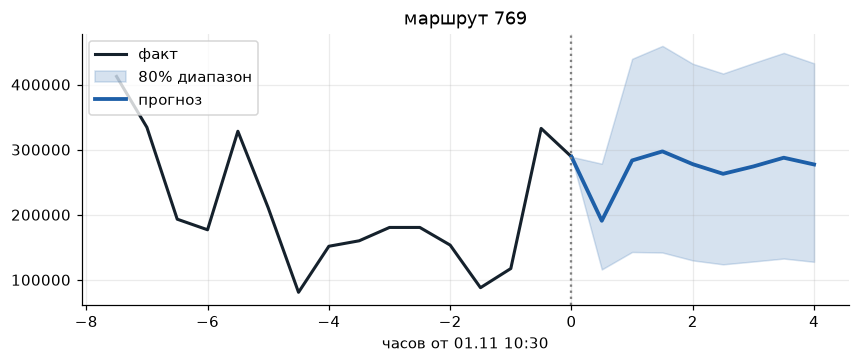

In [6]:
svc = Service.load(ROOT / "models/prod/service")
o = panel.n_times - 1
fc = svc.forecast(panel, cums, o)
r = int(np.argsort(fc["p50"].sum(1))[len(fc["p50"]) // 2])  # маршрут средней величины
hist = panel.y[r, o - 15 : o + 1]
t_h, t_f = np.arange(-15, 1) / 2, np.arange(1, 9) / 2
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(t_h, hist, color="#15212c", lw=2, label="факт")
ax.fill_between(np.r_[0, t_f], np.r_[hist[-1], fc["p10"][r]], np.r_[hist[-1], fc["p90"][r]], color="#1d5fa8", alpha=0.18, label="80% диапазон")
ax.plot(np.r_[0, t_f], np.r_[hist[-1], fc["p50"][r]], color="#1d5fa8", lw=2.5, label="прогноз")
ax.axvline(0, color="grey", ls=":"); ax.set_xlabel("часов от 01.11 10:30"); ax.set_title(f"маршрут {panel.routes[r]}")
ax.legend(loc="upper left")
plt.show()

## 4. Когда вызывать машину

В данных нет вместимости машин, времени подачи и груза у ворот, поэтому это **параметры** (в конфиге сервиса): кузов вмещает 2 часа среднего потока маршрута, машина едет 1 час после вызова, ждёт груз не дольше 2 часов. Груз у ворот восстанавливается из получасовых отгрузок.

**Правило.** Следующая машина вызывается, когда *груз у ворот + ожидаемый приход за время подачи* покрывает ещё один кузов сверх уже вызванных машин. Тогда машина приходит к моменту, когда кузов набран. «Ожидаемый приход» берётся из прогноза модели; его можно взять и из простых правил, это и есть сравнение.

**Симулятор** проигрывает реальные отгрузки недели 25–31 октября по всем 1000 маршрутам и считает:
- *простой* — сколько машина стоит у ворот, пока набирается кузов;
- *ожидание груза* — сколько полный кузов ждёт машину;
- *недогруз* — машина уехала неполной, не дождавшись груза.

Модели для прогноза обучены до начала недели, квантили прихода откалиброваны на предыдущей неделе.

In [7]:
names = {"reactive": "Вызов, когда кузов полон", "last_2h_pace": "Темп последних 2 часов",
         "same_time_last_week": "Как в это время неделю назад", "model_p50": "Модель (медиана)",
         "model_p25": "Модель, осторожно (25%)", "model_p75": "Модель, с запасом (75%)", "oracle": "Идеальный прогноз"}
pdays = BT["dispatch"]["per_day"]
t = pd.DataFrame(pdays).T.loc[list(names)]
t["потери, мин на машину"] = 60 * (t.idle_h + t.late_h) / t.trucks
t = t.rename(index=names)[["trucks", "idle_h", "late_h", "partial", "потери, мин на машину"]]
t.columns = ["машин в день", "простой, ч/день", "ожидание груза, ч/день", "недогруженных в день", "потери, мин на машину"]
t.round(1)

,машин в день,"простой, ч/день","ожидание груза, ч/день",недогруженных в день,"потери, мин на машину"
"Вызов, когда кузов полон",11555.6,0.0,11550.7,0.0,60.0
Темп последних 2 часов,11623.1,3051.0,2368.6,62.3,28.0
Как в это время неделю назад,11618.9,2481.7,2052.5,30.6,23.4
Модель (медиана),11612.2,1796.7,2122.8,6.4,20.3
"Модель, осторожно (25%)",11600.5,608.4,4122.3,2.5,24.5
"Модель, с запасом (75%)",11623.7,4027.8,863.7,27.9,25.2
Идеальный прогноз,11625.0,0.0,7.5,0.0,0.0


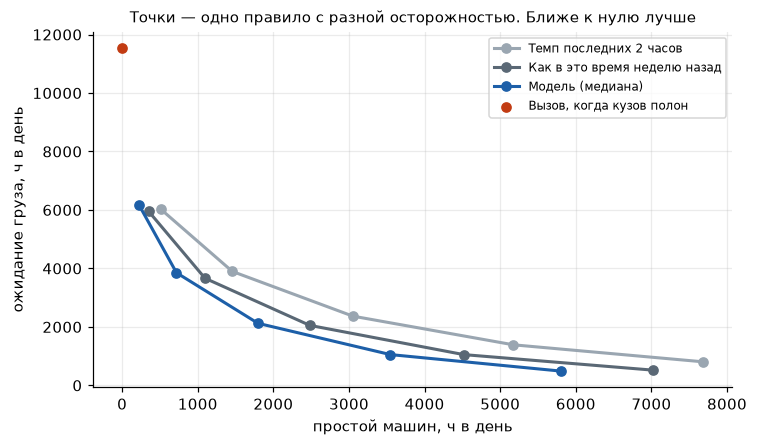

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
colors = {"last_2h_pace": "#9aa6b1", "same_time_last_week": "#5a6875", "model_p50": "#1d5fa8"}
for k, curve in BT["dispatch"]["curves"].items():
    ax.plot([c["idle_h"] for c in curve], [c["late_h"] for c in curve], "o-", color=colors[k], label=names[k], lw=2)
r0 = pdays["reactive"]
ax.scatter([r0["idle_h"]], [r0["late_h"]], color="#c23b12", zorder=3, label=names["reactive"])
ax.set_xlabel("простой машин, ч в день"); ax.set_ylabel("ожидание груза, ч в день")
ax.set_title("Точки — одно правило с разной осторожностью. Ближе к нулю лучше", fontsize=10)
ax.legend(fontsize=8)
plt.show()

Кривая модели лежит ниже и левее обоих простых правил при любой настройке осторожности: при том же простое машин груз ждёт меньше, и наоборот. Реактивный вызов «по факту» не даёт простоя, но каждый кузов ждёт машину весь час подачи.

Вывод не должен зависеть от выбранных параметров, поэтому та же проверка повторена при подаче от 30 минут до 2 часов и кузове от 1 до 4 часов потока:

In [9]:
sens = pd.DataFrame(BT["dispatch"]["sensitivity"])
sens = sens.rename(columns={**names, "lead_h": "подача, ч", "fill_hours": "кузов, ч потока"})
sens.round(1)

,"подача, ч","кузов, ч потока","Вызов, когда кузов полон",Темп последних 2 часов,Как в это время неделю назад,Модель (медиана),Идеальный прогноз
0,0.5,1.0,30.0,19.0,17.7,16.2,0.0
1,0.5,2.0,30.0,19.2,17.8,16.3,0.0
2,0.5,4.0,30.0,19.3,17.9,16.4,0.0
3,1.0,1.0,59.9,27.9,23.4,20.2,0.2
4,1.0,2.0,60.0,28.0,23.4,20.3,0.0
5,1.0,4.0,60.0,28.0,23.4,20.4,0.0
6,2.0,1.0,119.3,38.7,30.4,26.2,1.2
7,2.0,2.0,120.0,41.0,30.1,25.8,0.4
8,2.0,4.0,120.0,41.0,30.1,25.9,0.0


Модель лучше простых правил во всех 9 сочетаниях, и выигрыш растёт с временем подачи: чем раньше нужно решать, тем важнее знать будущее. При подаче 2 часа потери на машину — 26 минут против 30 у лучшего простого правила и 120 при вызове по факту.

## 5. Контроль качества

Главный урок лидерборда — промах по сумме дня. Поэтому сервис каждый день считает отдельно точность по точкам (WAPE), **знаковый перекос суммы** и долю фактов в 80%-диапазоне, и поднимает тревогу:
- средний перекос за 3 дня больше 2% → перекалибровать уровень;
- WAPE дня на 15% выше обычного → проверить данные, при повторе переобучить;
- в 80%-диапазон попало меньше 70% → пересчитать диапазоны;
- у маршрута пропуски в последних 4 часах → его прогноз заменяется сезонной базой.

Журнал за проверочную неделю (прогноз из 10:30):

In [10]:
proc = subprocess.run([PY, "scripts/pipeline.py", "monitor", "--daily"], cwd=ROOT, capture_output=True, text=True, encoding="utf-8")
mon = pd.read_csv(ROOT / "outputs/monitor_metrics.csv")
al = pd.read_csv(ROOT / "outputs/monitor_alerts.csv")
display(mon.round(4))
print("тревог:", len(al))

,origin,wape,bias,score,coverage
0,2025-10-25 10:30:00,0.3211,0.0084,0.3296,0.8049
1,2025-10-26 10:30:00,0.3238,-0.0010,0.3248,0.8171
2,2025-10-27 10:30:00,0.3216,-0.0021,0.3236,0.8068
3,2025-10-28 10:30:00,0.3147,-0.0058,0.3205,0.8062
4,2025-10-29 10:30:00,0.3215,0.0368,0.3582,0.8206
5,2025-10-30 10:30:00,0.3038,0.0077,0.3115,0.8282
6,2025-10-31 10:30:00,0.3183,0.0087,0.3270,0.8118


тревог: 0


Попробована и **отвергнута** поправка уровня внутри дня (по ошибке прогнозов последних 4 часов): на неделе калибровки она помогала, на проверочной ухудшила балл. Поэтому уровень корректируется по тревоге за несколько дней, а не каждые полчаса.

In [11]:
pd.DataFrame(BT["intraday"]["eval_10_30"], index=["балл", "|перекос|"]).rename(columns={"off": "без поправки", "on": "с поправкой"}).round(4)

,без поправки,с поправкой
балл,0.3276,0.3289
|перекос|,0.0103,0.0118


## 6. Пайплайн

```
python scripts/rolling.py --folds 2 --final   # прогнозы из каждого получаса 2 недель + модель на всех данных
python scripts/service_backtest.py            # диапазоны, симуляция вызова машин, отчёт reports/service/lean.json
python scripts/pipeline.py train              # пакет сервиса models/prod/service: модель, диапазоны, параметры
python scripts/pipeline.py forecast --at "2025-11-01 10:30"   # прогноз + план машин в outputs/
python scripts/pipeline.py monitor --daily    # метрики и тревоги
python scripts/pipeline.py report             # пульт диспетчера outputs/dispatch_board.html
```

| Шаг | Как часто | Время | Что выходит |
|---|---|---|---|
| `train` | раз в сутки | ≈4 мин, CPU | модель 12 МБ + таблицы диапазонов |
| `forecast` | каждые 30 мин | 2 с на 1000 маршрутов | `forecast_*.csv` (p10/p50/p90), `trucks_*.csv` (когда вызывать) |
| `monitor` | раз в сутки | секунды | метрики, тревоги |

Выходы прогноза:

In [12]:
stamp = panel.times[-1].strftime("%Y%m%d_%H%M")
display(pd.read_csv(ROOT / f"outputs/forecast_{stamp}.csv").head(8))
plan = pd.read_csv(ROOT / f"outputs/trucks_{stamp}.csv")
print(f"вызвать сейчас: {plan.call_now.sum()} маршрутов, в ближайшие 4 часа: {plan.call_at.notna().sum()}")
plan.sort_values(["call_now", "backlog_loads"], ascending=False).head(8)

,route_id,timestamp,p10,p50,p90
0,0,2025-11-01 11:00:00,108700.663011,201460.640625,311105.896329
1,0,2025-11-01 11:30:00,72669.605529,170655.968750,279679.323346
2,0,2025-11-01 12:00:00,82799.674295,207457.000000,339035.654269
3,0,2025-11-01 12:30:00,73469.827669,188623.546875,311961.435666
4,0,2025-11-01 13:00:00,68317.694134,174444.890625,294176.221251
5,0,2025-11-01 13:30:00,66538.474903,171914.765625,288360.598241
6,0,2025-11-01 14:00:00,59433.284798,155631.796875,259003.245661
7,0,2025-11-01 14:30:00,56703.941678,148278.343750,246615.274448


вызвать сейчас: 274 маршрутов, в ближайшие 4 часа: 994


,route_id,capacity,backlog,backlog_loads,inflow_4h_p50,inflow_4h_p90,trucks_on_the_way,trucks_at_dock,call_at,call_now,loads_4h_p90,stale_data
485,485,813062.312500,2.205239e+06,2.712263,1.523656e+06,1.794584e+06,2,0,2025-11-01 10:30:00,True,4.919454,False
123,123,719651.500000,1.272785e+06,1.768613,1.331621e+06,1.597950e+06,1,0,2025-11-01 10:30:00,True,3.989063,False
75,75,143892.296875,2.178380e+05,1.513896,1.582853e+05,2.151059e+05,0,0,2025-11-01 10:30:00,True,3.008805,False
452,452,215465.171875,3.063048e+05,1.421598,4.136828e+05,5.621826e+05,0,0,2025-11-01 10:30:00,True,4.030755,False
649,649,464600.625000,6.366734e+05,1.370367,1.175481e+06,1.483877e+06,1,0,2025-11-01 10:30:00,True,4.564243,False
635,635,226812.687500,2.975798e+05,1.312007,4.475043e+05,6.081449e+05,0,0,2025-11-01 10:30:00,True,3.993271,False
425,425,514244.843750,6.399081e+05,1.244365,9.518210e+05,1.161706e+06,0,0,2025-11-01 10:30:00,True,3.503418,False
978,978,413579.437500,4.945592e+05,1.195802,8.304089e+05,1.048273e+06,0,0,2025-11-01 10:30:00,True,3.730438,False


## 7. Итог

- **Для соревнования**: финальная посылка — ансамбль v2 (лидерборд 0.323). Порядок моделей устойчив к делению на публичную и приватную части.
- **Для бизнеса**: одна LightGBM на CPU, прогноз каждые полчаса за 2 секунды, честные диапазоны и правило вызова машин, которое на истории сокращает потери с 60 до 20 минут на машину при подаче 1 час и даёт в 5–10 раз меньше недогруженных машин, чем простые правила.
- **Ограничения**: вместимость, время подачи и груз у ворот заданы допущениями; в работе их берут из транспортной и складской систем. Объёмы — в единицах данных соревнования.